<a href="https://colab.research.google.com/github/ASamyASalem/Compact-Feature-Matching/blob/main/01_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Drive Connection

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


# Libraries


In [2]:
from pathlib import Path
import zipfile

import cv2
import numpy as np
import matplotlib.pyplot as plt

print(f"OpenCV version: {cv2.__version__}")
print("Libraries imported successfully")

OpenCV version: 5.0.0
Libraries imported successfully


# Data Read Test


In [6]:
project_dir = Path("/content/drive/MyDrive/DIP Project/Compact_Feature_Matching")
data_dir = project_dir / "data"
zip_path = data_dir / "hpatches-sequences-release.zip"

print(f"Project folder exists: {project_dir.exists()}")
print(f"Dataset ZIP exists: {zip_path.exists()}")

if data_dir.exists():
  print("\n Files inside data:")
  for item in data_dir.iterdir():
    print(item.name)

Project folder exists: True
Dataset ZIP exists: True

 Files inside data:
hpatches-sequences-release.zip


# ZIP file Extraction

In [7]:
extract_dir = Path("/content/hpatches_data")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
  archive.extractall(extract_dir)

print("Extraction completed.")

Extraction completed.


# Find Scene Folders

In [8]:
sequences = sorted({
    image_path.parent
    for image_path in extract_dir.rglob("1.ppm")
})

illumination_sequences = [
    folder for folder in sequences
    if folder.name.startswith("i_")
]

viewpoint_sequences = [
    folder for folder in sequences
    if folder.name.startswith("v_")
]

print(f"Total sequences: {len(sequences)}")
print(f"Illumination sequences: {len(illumination_sequences)}")
print(f"Viewpoint sequences: {len(viewpoint_sequences)}")

if not sequences:
  raise FileNotFoundError("No sequences containing 1.ppm were found.")

print(f"\n First sequence: {sequences[0].name}")


Total sequences: 116
Illumination sequences: 57
Viewpoint sequences: 59

 First sequence: i_ajuntament


# Read and Display the first two images

sequence: i_ajuntament
Image 1 shape: (480, 640)
Image 2 shape: (480, 640)


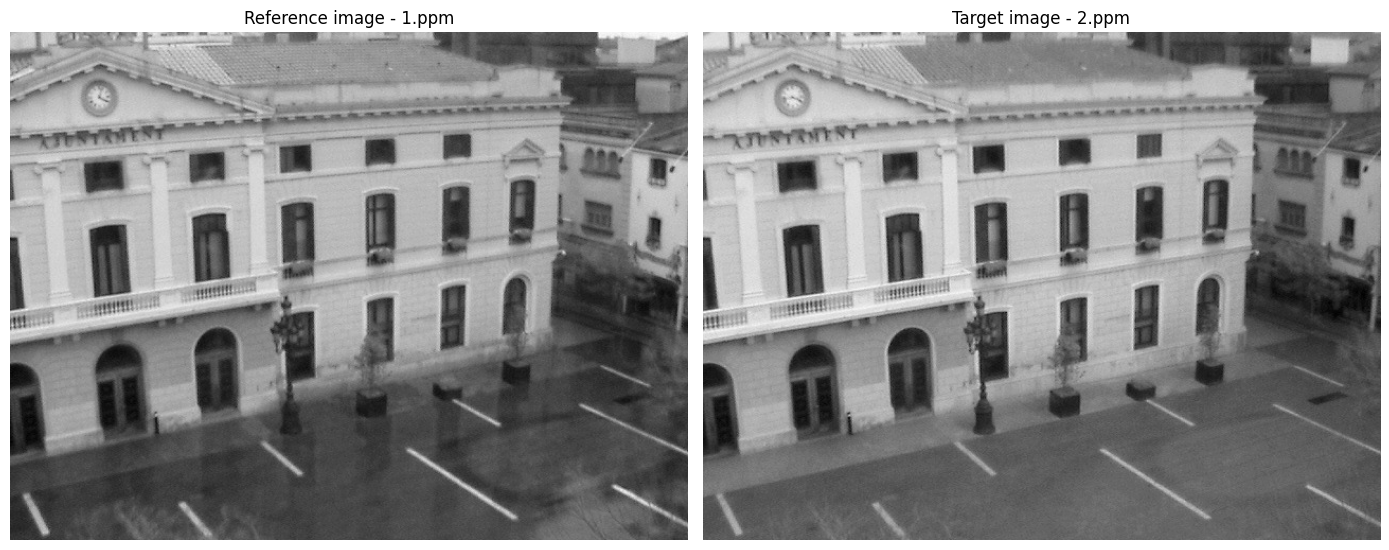

In [11]:
sequence = sequences[0]
img1 = cv2.imread(str(sequence / "1.ppm"), cv2.IMREAD_GRAYSCALE)

img2 = cv2.imread(str(sequence / "2.ppm"), cv2.IMREAD_GRAYSCALE)
if img1 is None or img2 is None:
  raise FileNotFoundError("Could not read one or both images.")

print(f"sequence: {sequence.name}")
print(f"Image 1 shape: {img1.shape}")
print(f"Image 2 shape: {img2.shape}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("Reference image - 1.ppm")


axes[1].imshow(img2, cmap="gray")
axes[1].set_title("Target image - 2.ppm")

for ax in axes:
  ax.axis("off")

plt.tight_layout()
plt.show()

# Ground-truth Homography

In [12]:
# path of transformation from image 1 to image 2
homography_path = sequence / "H_1_2"

# Read the transformation matrix
H_gt = np.loadtxt(homography_path)

print(f"Homography file: {homography_path.name}")
print(f"Matrix shape: {H_gt.shape}")
print(f"Ground-truth Homography: {H_gt}")

Homography file: H_1_2
Matrix shape: (3, 3)
Ground-truth Homography: [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [13]:
# Image dimensions: height first, then width
height, width = img1.shape

# Coordinates of a point near the center
x1 = width // 2
y1 = height // 2

# Represent the point using homogeneous coordinates
point1 = np.array([x1, y1, 1.0])
print(f"Point in image 1: {point1}")

Point in image 1: [320. 240.   1.]


In [14]:
# Apply the homography using matrix multiplication
point2_h = H_gt @ point1

# Convert back to ordinary pixel coordinates
if abs(point2_h[2]) < 1e-10:
  raise ValueError("This point maps too close to infinity.")

x2 = point2_h[0] / point2_h[2]
y2 = point2_h[1] / point2_h[2]

print(f"Image 1 point: x={x1}, y={y1}")
print(f"Image 2 point: x={x2:.2f},y={y2:.2f}")

Image 1 point: x=320, y=240
Image 2 point: x=320.00,y=240.00


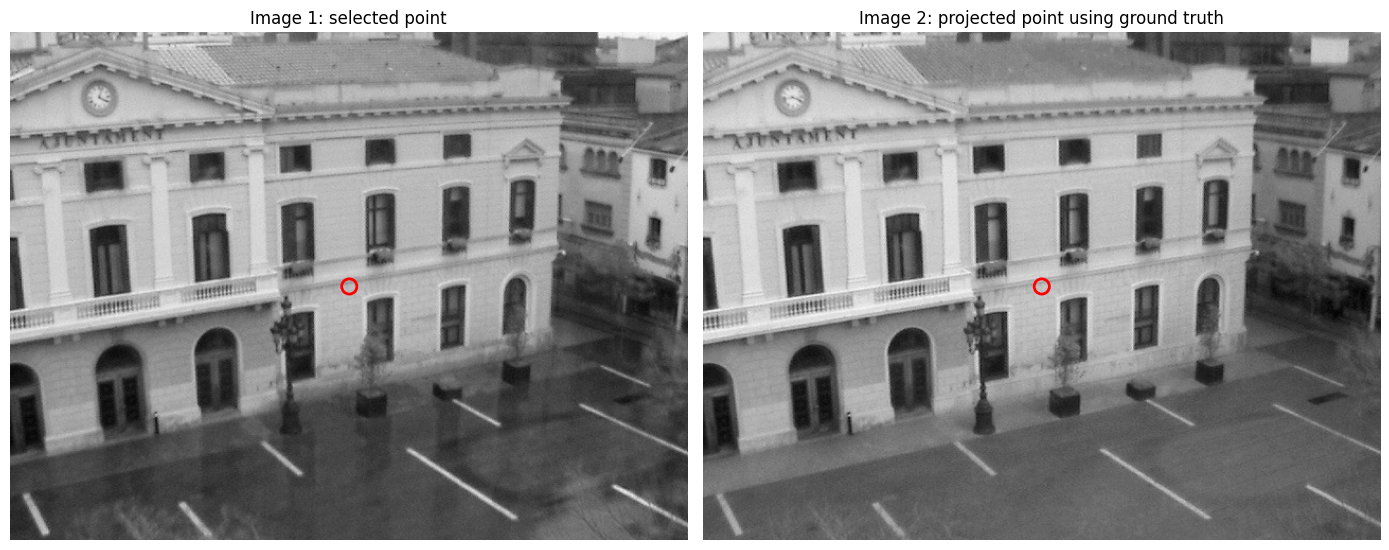

In [15]:
# Check whether the projected point lies inside image 2
height2, width2 = img2.shape

inside_image2 = (
    0 <= x2 < width2
    and 0 <= y2 < height2
)
fig, axes = plt.subplots(1, 2, figsize=(14,6))

# Show the original point
axes[0].imshow(img1, cmap="gray")
axes[0].scatter(
    x1, y1,
    s=120,
    facecolors="none",
    edgecolors="red",
    linewidths=2
)
axes[0].set_title("Image 1: selected point")

# Show the corresponding point if it is visible
axes[1].imshow(img2, cmap="gray")

if inside_image2:
  axes[1].scatter(
      x2, y2,
      s=120,
      facecolors="none",
      edgecolors="red",
      linewidths=2
  )

  axes[1].set_title("Image 2: projected point using ground truth")
else:
  axes[1].set_title("Image 2: projected point is outside the image")

for ax in axes:
  ax.axis("off")

plt.tight_layout()
plt.show()